Starting Optimization...
Step  1 | Cost_L = 0.0089888
Step  2 | Cost_L = 0.0089888
Step  3 | Cost_L = 0.0070019
Step  4 | Cost_L = 0.0032180
Step  5 | Cost_L = 0.0008581
Step  6 | Cost_L = 0.0005735
Step  7 | Cost_L = 0.0005735
Step  8 | Cost_L = 0.0002451
Step  9 | Cost_L = 0.0002451
Step 10 | Cost_L = 0.0001570
Step 11 | Cost_L = 0.0001253
Step 12 | Cost_L = 0.0001090
Step 13 | Cost_L = 0.0000628
Step 14 | Cost_L = 0.0000425
Step 15 | Cost_L = 0.0000425
Step 16 | Cost_L = 0.0000175
Step 17 | Cost_L = 0.0000101
Step 18 | Cost_L = 0.0000043
Step 19 | Cost_L = 0.0000043
Step 20 | Cost_L = 0.0000008
Step 21 | Cost_L = 0.0000008

--- Results Comparison ---
Classical Probabilities (x_n^2):     [0.08446 0.08446 0.16554 0.16554 0.08446 0.08446 0.16554 0.16554]
Quantum Probabilities   (|<x|n>|^2): [0.08273 0.08473 0.16618 0.16766 0.08501 0.08446 0.16473 0.1645 ]


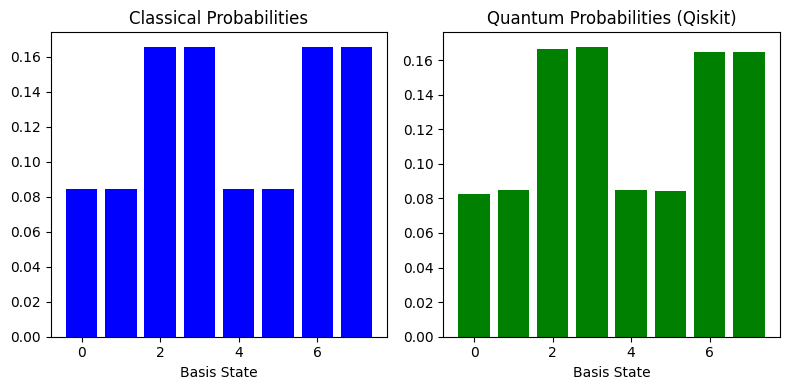

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorSampler

# ==========================================
# 1. Hyper-parameters & Problem Setup
# ==========================================
n_qubits = 3             # System qubits
ancilla_idx = n_qubits   # Ancilla qubit index (qubit 3)
tot_qubits = n_qubits + 1 
c = np.array([1.0, 0.2, 0.2])  # Coefficients for A = c[0]A0 + c[1]A1 + c[2]A2

# Setup classical system matrices
Id = np.identity(2)
Z = np.array([[1, 0], [0, -1]])
X = np.array([[0, 1], [1, 0]])

A_0 = np.identity(8)
A_1 = np.kron(np.kron(X, Z), Id)
A_2 = np.kron(np.kron(X, Id), Id)
A_num = c[0] * A_0 + c[1] * A_1 + c[2] * A_2
b_vec = np.ones(8) / np.sqrt(8)


# ==========================================
# 2. Quantum Circuit Subroutines
# ==========================================
def apply_U_b(qc: QuantumCircuit):
    """Prepares the problem state |b> = U_b |0> = H^{⊗ n} |0>."""
    for idx in range(n_qubits):
        qc.h(idx)

def apply_CA(qc: QuantumCircuit, idx: int):
    """Applies controlled-A_l operations conditioned on the ancilla qubit."""
    if idx == 0:
        pass  # Identity
    elif idx == 1:
        qc.cx(ancilla_idx, 0)
        qc.cz(ancilla_idx, 1)
    elif idx == 2:
        qc.cx(ancilla_idx, 0)

def apply_variational_block(qc: QuantumCircuit, weights: np.ndarray):
    """Ansatz circuit mapping ground state |0> to guess state |x> = V(w)|0>."""
    for idx in range(n_qubits):
        qc.h(idx)
    for idx, w in enumerate(weights):
        qc.ry(w, idx)


# ==========================================
# 3. Hadamard Test & Cost Function
# ==========================================
def local_hadamard_test_circuit(weights: np.ndarray, l: int, lp: int, j: int, part: str) -> QuantumCircuit:
    """Builds the Hadamard test circuit for estimating coefficient mu_{l, l', j}."""
    qc = QuantumCircuit(tot_qubits)

    # First Hadamard on ancilla
    qc.h(ancilla_idx)

    # Phase shift for imaginary part
    if part.lower() in ["im", "imag"]:
        qc.p(-np.pi / 2, ancilla_idx)

    # Variational block V(w)
    apply_variational_block(qc, weights)

    # Controlled A_l
    apply_CA(qc, l)

    # Adjoint(U_b) -- in this specific problem, U_b = U_b^\dagger
    apply_U_b(qc)

    # Controlled-Z_j (if j != -1)
    if j != -1:
        qc.cz(ancilla_idx, j)

    # U_b
    apply_U_b(qc)

    # Controlled A_{l'}^\dagger
    apply_CA(qc, lp)

    # Second Hadamard on ancilla
    qc.h(ancilla_idx)

    return qc

def get_hadamard_test_expval(weights: np.ndarray, l: int, lp: int, j: int, part: str) -> float:
    """Evaluates <Z> on ancilla using Statevector simulation."""
    qc = local_hadamard_test_circuit(weights, l, lp, j, part)
    sv = Statevector.from_instruction(qc)
    
    # Pauli Z on ancilla qubit
    pauli_str = ["I"] * tot_qubits
    pauli_str[ancilla_idx] = "Z"
    op = SparsePauliOp("".join(reversed(pauli_str))) # Qiskit qubit order is right-to-left
    
    return float(np.real(sv.expectation_value(op)))

def mu(weights: np.ndarray, l: int, lp: int, j: int) -> complex:
    """Computes complex coefficient mu_{l, l', j}."""
    re = get_hadamard_test_expval(weights, l, lp, j, part="Re")
    im = get_hadamard_test_expval(weights, l, lp, j, part="Im")
    return re + 1.0j * im

def psi_norm(weights: np.ndarray) -> float:
    """Computes normalization factor <psi|psi> where |psi> = A|x>."""
    norm = 0.0
    for l in range(len(c)):
        for lp in range(len(c)):
            norm += c[l] * np.conj(c[lp]) * mu(weights, l, lp, -1)
    return float(np.abs(norm))

def cost_loc(weights: np.ndarray) -> float:
    """Local cost function C_L for optimization."""
    mu_sum = 0.0
    for l in range(len(c)):
        for lp in range(len(c)):
            for j in range(n_qubits):
                mu_sum += c[l] * np.conj(c[lp]) * mu(weights, l, lp, j)
    
    mu_sum = np.abs(mu_sum)
    return 0.5 - 0.5 * mu_sum / (n_qubits * psi_norm(weights))


# ==========================================
# 4. Variational Optimization (SciPy)
# ==========================================
np.random.seed(0)
q_delta = 0.001
initial_weights = q_delta * np.random.randn(n_qubits)

cost_history = []
def callback(weights):
    c_val = cost_loc(weights)
    cost_history.append(c_val)
    print(f"Step {len(cost_history):2d} | Cost_L = {c_val:.7f}")

print("Starting Optimization...")
res = minimize(cost_loc, initial_weights, method="COBYLA", callback=callback, options={"maxiter": 30})
opt_weights = res.x


# ==========================================
# 5. Classical Solution
# ==========================================
A_inv = np.linalg.inv(A_num)
x_class = np.dot(A_inv, b_vec)
c_probs = (x_class / np.linalg.norm(x_class)) ** 2


# ==========================================
# 6. Quantum Solution & Comparison
# ==========================================
# Build circuit to prepare |x> with optimized weights
ansatz_qc = QuantumCircuit(n_qubits)
apply_variational_block(ansatz_qc, opt_weights)
ansatz_qc.measure_all()

# Sample using Qiskit's Sampler primitive
sampler = StatevectorSampler()
job = sampler.run([ansatz_qc], shots=100000)
result = job.result()
counts = result[0].data.meas.get_counts()

# Convert counts to bitstring probabilities matching [0, 2^n - 1]
q_probs = np.zeros(2**n_qubits)
for bitstr, count in counts.items():
    idx = int(bitstr, 2)
    q_probs[idx] = count / 100000

print("\n--- Results Comparison ---")
print("Classical Probabilities (x_n^2):    ", np.round(c_probs, 5))
print("Quantum Probabilities   (|<x|n>|^2):", np.round(q_probs, 5))

# Plotting Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
ax1.bar(np.arange(2**n_qubits), c_probs, color="blue")
ax1.set_title("Classical Probabilities")
ax1.set_xlabel("Basis State")

ax2.bar(np.arange(2**n_qubits), q_probs, color="green")
ax2.set_title("Quantum Probabilities (Qiskit)")
ax2.set_xlabel("Basis State")
plt.tight_layout()
plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime import QiskitRuntimeService

# ==========================================
# 1. Hyper-parameters & Problem Setup
# ==========================================
n_qubits = 3             # System qubits
ancilla_idx = n_qubits   # Ancilla qubit index (qubit 3)
tot_qubits = n_qubits + 1 
shots = 100000
c = np.array([1.0, 0.2, 0.2])

# Classical setup
Id, Z, X = np.identity(2), np.array([[1, 0], [0, -1]]), np.array([[0, 1], [1, 0]])
A_0, A_1, A_2 = np.identity(8), np.kron(np.kron(X, Z), Id), np.kron(np.kron(X, Id), Id)
A_num = c[0] * A_0 + c[1] * A_1 + c[2] * A_2
b_vec = np.ones(8) / np.sqrt(8)


# ==========================================
# 2. Hardware / Simulator Setup
# ==========================================
# Set up AerSimulator with a Real Hardware Noise Model
# (To run on actual hardware: replace `backend` with service.backend("ibm_brisbane"))
try:
    service = QiskitRuntimeService()
    real_backend = service.least_busy(operational=True, simulator=False)
    noise_model = NoiseModel.from_backend(real_backend)
    backend = AerSimulator(noise_model=noise_model)
    print(f"Using AerSimulator with noise model from: {real_backend.name}")
except Exception:
    # Fallback to standard noisy AerSimulator if no IBM Quantum account is saved
    print("No IBM account saved. Using ideal AerSimulator (Noise-Free).")
    backend = AerSimulator()


# ==========================================
# 3. Quantum Circuit Subroutines
# ==========================================
def apply_U_b(qc: QuantumCircuit):
    for idx in range(n_qubits):
        qc.h(idx)

def apply_CA(qc: QuantumCircuit, idx: int):
    if idx == 1:
        qc.cx(ancilla_idx, 0)
        qc.cz(ancilla_idx, 1)
    elif idx == 2:
        qc.cx(ancilla_idx, 0)

def apply_variational_block(qc: QuantumCircuit, weights: np.ndarray):
    for idx in range(n_qubits):
        qc.h(idx)
    for idx, w in enumerate(weights):
        qc.ry(w, idx)


# ==========================================
# 4. Measurement & Cost Function via AerSimulator
# ==========================================
def local_hadamard_test_circuit(weights: np.ndarray, l: int, lp: int, j: int, part: str) -> QuantumCircuit:
    qc = QuantumCircuit(tot_qubits, 1)  # 1 classical bit to measure ancilla

    qc.h(ancilla_idx)
    if part.lower() in ["im", "imag"]:
        qc.p(-np.pi / 2, ancilla_idx)

    apply_variational_block(qc, weights)
    apply_CA(qc, l)
    apply_U_b(qc)

    if j != -1:
        qc.cz(ancilla_idx, j)

    apply_U_b(qc)
    apply_CA(qc, lp)
    qc.h(ancilla_idx)

    # Measure ancilla qubit into classical bit 0
    qc.measure(ancilla_idx, 0)
    return qc

def get_hadamard_test_expval(weights: np.ndarray, l: int, lp: int, j: int, part: str) -> float:
    """Executes circuit on AerSimulator and calculates expectation value <Z> from counts."""
    qc = local_hadamard_test_circuit(weights, l, lp, j, part)
    
    # Run shot-based simulation on backend
    result = backend.run(qc, shots=shots).result()
    counts = result.get_counts()
    
    # <Z> = (P(0) - P(1))
    p0 = counts.get('0', 0) / shots
    p1 = counts.get('1', 0) / shots
    return p0 - p1

def mu(weights: np.ndarray, l: int, lp: int, j: int) -> complex:
    re = get_hadamard_test_expval(weights, l, lp, j, part="Re")
    im = get_hadamard_test_expval(weights, l, lp, j, part="Im")
    return re + 1.0j * im

def psi_norm(weights: np.ndarray) -> float:
    norm = 0.0
    for l in range(len(c)):
        for lp in range(len(c)):
            norm += c[l] * np.conj(c[lp]) * mu(weights, l, lp, -1)
    return float(np.abs(norm))

def cost_loc(weights: np.ndarray) -> float:
    mu_sum = 0.0
    for l in range(len(c)):
        for lp in range(len(c)):
            for j in range(n_qubits):
                mu_sum += c[l] * np.conj(c[lp]) * mu(weights, l, lp, j)
    
    mu_sum = np.abs(mu_sum)
    return 0.5 - 0.5 * mu_sum / (n_qubits * psi_norm(weights))


# ==========================================
# 5. Optimization
# ==========================================
np.random.seed(0)
initial_weights = 0.001 * np.random.randn(n_qubits)

cost_history = []
def callback(weights):
    c_val = cost_loc(weights)
    cost_history.append(c_val)
    print(f"Step {len(cost_history):2d} | Cost_L = {c_val:.7f}")

print("Starting Optimization...")
res = minimize(cost_loc, initial_weights, method="COBYLA", callback=callback, options={"maxiter": 20})
opt_weights = res.x


# ==========================================
# 6. Evaluation & Comparison
# ==========================================
# Classical solution
A_inv = np.linalg.inv(A_num)
x_class = np.dot(A_inv, b_vec)
c_probs = (x_class / np.linalg.norm(x_class)) ** 2

# Final state sampling on backend
ansatz_qc = QuantumCircuit(n_qubits, n_qubits)
apply_variational_block(ansatz_qc, opt_weights)
ansatz_qc.measure(range(n_qubits), range(n_qubits))

result = backend.run(ansatz_qc, shots=shots).result()
counts = result.get_counts()

q_probs = np.zeros(2**n_qubits)
for bitstr, count in counts.items():
    idx = int(bitstr, 2)
    q_probs[idx] = count / shots

print("\n--- Results Comparison ---")
print("Classical Probabilities: ", np.round(c_probs, 4))
print("Hardware Sim Probabilities:", np.round(q_probs, 4))

No IBM account saved. Using ideal AerSimulator (Noise-Free).
Starting Optimization...
Step  1 | Cost_L = 0.0086834
Step  2 | Cost_L = 0.0091213
Step  3 | Cost_L = 0.0090868
Step  4 | Cost_L = 0.0052489
Step  5 | Cost_L = 0.0025271
Step  6 | Cost_L = 0.0014626
Step  7 | Cost_L = 0.0001664
Step  8 | Cost_L = -0.0003693
Step  9 | Cost_L = -0.0000487
Step 10 | Cost_L = -0.0000414
Step 11 | Cost_L = 0.0002445
Step 12 | Cost_L = 0.0002028

--- Results Comparison ---
Classical Probabilities:  [0.0845 0.0845 0.1655 0.1655 0.0845 0.0845 0.1655 0.1655]
Hardware Sim Probabilities: [0.0892 0.0841 0.1628 0.1568 0.093  0.0892 0.1684 0.1564]


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit_aer.noise as noise

# ==========================================
# 1. Setup & Custom Noise Model Definition
# ==========================================
n_qubits = 3             # System qubits
ancilla_idx = n_qubits   # Ancilla qubit index (qubit 3)
tot_qubits = n_qubits + 1 
shots = 100000
c = np.array([1.0, 0.2, 0.2])  # Linear combination coefficients

# Gates noise error rates
p_1qubit = 1e-5  # 10^-5 for 1-qubit gates
p_2qubit = 1e-4  # 10^-4 for 2-qubit gates

# Construct Qiskit Aer depolarizing noise model
noise_model = noise.NoiseModel()
error_1 = noise.depolarizing_error(p_1qubit, 1)
error_2 = noise.depolarizing_error(p_2qubit, 2)

# Apply 1-qubit gate errors
noise_model.add_all_qubit_quantum_error(error_1, ["h", "ry", "p"])
# Apply 2-qubit gate errors
noise_model.add_all_qubit_quantum_error(error_2, ["cx", "cz"])

# Simulators
ideal_backend = AerSimulator()
noisy_backend = AerSimulator(noise_model=noise_model)

# Classical problem matrices
Id, Z, X = np.identity(2), np.array([[1, 0], [0, -1]]), np.array([[0, 1], [1, 0]])
A_0, A_1, A_2 = np.identity(8), np.kron(np.kron(X, Z), Id), np.kron(np.kron(X, Id), Id)
A_num = c[0] * A_0 + c[1] * A_1 + c[2] * A_2
b_vec = np.ones(8) / np.sqrt(8)


# ==========================================
# 2. Quantum Circuit Subroutines
# ==========================================
def apply_U_b(qc: QuantumCircuit):
    for idx in range(n_qubits):
        qc.h(idx)

def apply_CA(qc: QuantumCircuit, idx: int):
    if idx == 1:
        qc.cx(ancilla_idx, 0)
        qc.cz(ancilla_idx, 1)
    elif idx == 2:
        qc.cx(ancilla_idx, 0)

def apply_variational_block(qc: QuantumCircuit, weights: np.ndarray):
    for idx in range(n_qubits):
        qc.h(idx)
    for idx, w in enumerate(weights):
        qc.ry(w, idx)



In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit_aer.noise as noise

# ==========================================
# 1. Setup & Custom Noise Model Definition
# ==========================================
n_qubits = 3             # System qubits
ancilla_idx = n_qubits   # Ancilla qubit index (qubit 3)
tot_qubits = n_qubits + 1 
shots = 100000
c = np.array([1.0, 0.2, 0.2])  # Linear combination coefficients

# Gates noise error rates
p_1qubit = 1e-5  # 10^-5 for 1-qubit gates
p_2qubit = 1e-4  # 10^-4 for 2-qubit gates

# Construct Qiskit Aer depolarizing noise model
noise_model = noise.NoiseModel()
error_1 = noise.depolarizing_error(p_1qubit, 1)
error_2 = noise.depolarizing_error(p_2qubit, 2)

# Apply 1-qubit gate errors
noise_model.add_all_qubit_quantum_error(error_1, ["h", "ry", "p"])
# Apply 2-qubit gate errors
noise_model.add_all_qubit_quantum_error(error_2, ["cx", "cz"])

# Simulators
ideal_backend = AerSimulator()
noisy_backend = AerSimulator(noise_model=noise_model)

# Classical problem matrices
Id, Z, X = np.identity(2), np.array([[1, 0], [0, -1]]), np.array([[0, 1], [1, 0]])
A_0, A_1, A_2 = np.identity(8), np.kron(np.kron(X, Z), Id), np.kron(np.kron(X, Id), Id)
A_num = c[0] * A_0 + c[1] * A_1 + c[2] * A_2
b_vec = np.ones(8) / np.sqrt(8)


# ==========================================
# 2. Quantum Circuit Subroutines
# ==========================================
def apply_U_b(qc: QuantumCircuit):
    for idx in range(n_qubits):
        qc.h(idx)

def apply_CA(qc: QuantumCircuit, idx: int):
    if idx == 1:
        qc.cx(ancilla_idx, 0)
        qc.cz(ancilla_idx, 1)
    elif idx == 2:
        qc.cx(ancilla_idx, 0)

def apply_variational_block(qc: QuantumCircuit, weights: np.ndarray):
    for idx in range(n_qubits):
        qc.h(idx)
    for idx, w in enumerate(weights):
        qc.ry(w, idx)


# ==========================================
# 3. Hadamard Test & Cost Function Evaluation
# ==========================================
def local_hadamard_test_circuit(weights: np.ndarray, l: int, lp: int, j: int, part: str) -> QuantumCircuit:
    qc = QuantumCircuit(tot_qubits, 1)

    qc.h(ancilla_idx)
    if part.lower() in ["im", "imag"]:
        qc.p(-np.pi / 2, ancilla_idx)

    apply_variational_block(qc, weights)
    apply_CA(qc, l)
    apply_U_b(qc)

    if j != -1:
        qc.cz(ancilla_idx, j)

    apply_U_b(qc)
    apply_CA(qc, lp)
    qc.h(ancilla_idx)

    qc.measure(ancilla_idx, 0)
    return qc

--- Circuit 1: Subroutines Demonstration ---


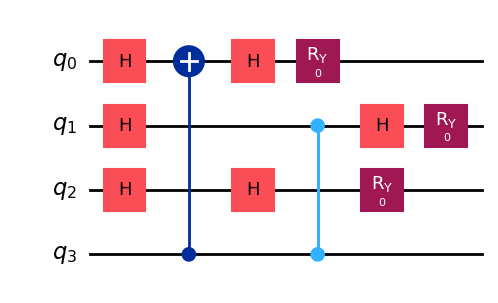

In [5]:
# ==========================================
# Circuit Visualizations
# ==========================================
dummy_weights = np.zeros(n_qubits)

# Circuit 1: Combined Subroutines (apply_U_b, apply_CA, apply_variational_block)
demo_qc = QuantumCircuit(tot_qubits)
apply_U_b(demo_qc)
apply_CA(demo_qc, idx=1)
apply_variational_block(demo_qc, dummy_weights)

print("--- Circuit 1: Subroutines Demonstration ---")
demo_qc.draw(output="mpl", style="iqp", fold=False)


--- Circuit 2: Full Hadamard Test Circuit ---


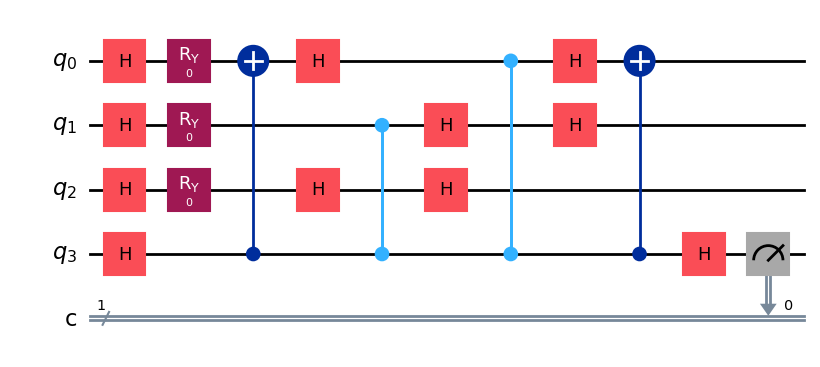

In [6]:
# Circuit 2: Full Hadamard Test Circuit
hadamard_demo_qc = local_hadamard_test_circuit(dummy_weights, l=1, lp=2, j=0, part="Re")

print("\n--- Circuit 2: Full Hadamard Test Circuit ---")
hadamard_demo_qc.draw(output="mpl", style="iqp", fold=False)

--- Starting VQLS Optimization (25 steps) ---
Step  1 | Cost_L = 0.0091159
Step  2 | Cost_L = 0.0091669
Step  3 | Cost_L = 0.0062748
Step  4 | Cost_L = 0.0037160
Step  5 | Cost_L = 0.0003859
Step  6 | Cost_L = 0.0001904
Step  7 | Cost_L = 0.0001188
Step  8 | Cost_L = 0.0003849
Step  9 | Cost_L = 0.0000556
Step 10 | Cost_L = 0.0004242
Step 11 | Cost_L = 0.0003800
Step 12 | Cost_L = 0.0008282
Step 13 | Cost_L = 0.0009613
Step 14 | Cost_L = -0.0002272

--- Results Comparison ---
Classical Probabilities : [0.0845 0.0845 0.1655 0.1655 0.0845 0.0845 0.1655 0.1655]
Quantum Ideal (No Noise): [0.094  0.0948 0.1742 0.1727 0.0814 0.0822 0.1509 0.1497]
Quantum Noisy (With Gate Noise): [0.0952 0.0955 0.1731 0.1744 0.0817 0.08   0.1507 0.1495]


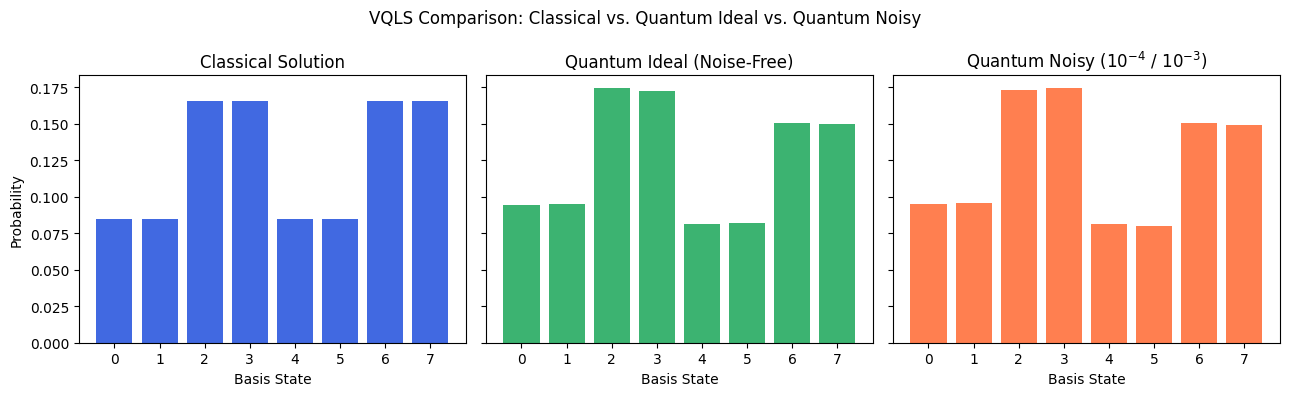

In [7]:
def get_hadamard_test_expval(weights: np.ndarray, l: int, lp: int, j: int, part: str, backend) -> float:
    qc = local_hadamard_test_circuit(weights, l, lp, j, part)
    result = backend.run(qc, shots=shots).result()
    counts = result.get_counts()
    
    p0 = counts.get('0', 0) / shots
    p1 = counts.get('1', 0) / shots
    return p0 - p1

def mu(weights: np.ndarray, l: int, lp: int, j: int, backend) -> complex:
    re = get_hadamard_test_expval(weights, l, lp, j, "Re", backend)
    im = get_hadamard_test_expval(weights, l, lp, j, "Im", backend)
    return re + 1.0j * im

def psi_norm(weights: np.ndarray, backend) -> float:
    norm = 0.0
    for l in range(len(c)):
        for lp in range(len(c)):
            norm += c[l] * np.conj(c[lp]) * mu(weights, l, lp, -1, backend)
    return float(np.abs(norm))

def cost_loc(weights: np.ndarray, backend) -> float:
    mu_sum = 0.0
    for l in range(len(c)):
        for lp in range(len(c)):
            for j in range(n_qubits):
                mu_sum += c[l] * np.conj(c[lp]) * mu(weights, l, lp, j, backend)
    
    mu_sum = np.abs(mu_sum)
    return 0.5 - 0.5 * mu_sum / (n_qubits * psi_norm(weights, backend))


# ==========================================
# 4. Optimization (25 Max Iterations / Steps)
# ==========================================
np.random.seed(0)
initial_weights = 0.001 * np.random.randn(n_qubits)

cost_history = []
def callback(weights):
    c_val = cost_loc(weights, ideal_backend)
    cost_history.append(c_val)
    print(f"Step {len(cost_history):2d} | Cost_L = {c_val:.7f}")

print("--- Starting VQLS Optimization (25 steps) ---")
res = minimize(
    lambda w: cost_loc(w, ideal_backend), 
    initial_weights, 
    method="COBYLA", 
    callback=callback, 
    options={"maxiter": 25}
)
opt_weights = res.x


# ==========================================
# 5. Compute Probabilities for Comparison
# ==========================================
# A. Classical Matrix Inversion Solution
A_inv = np.linalg.inv(A_num)
x_class = np.dot(A_inv, b_vec)
c_probs = (x_class / np.linalg.norm(x_class)) ** 2

# Helper function to sample quantum ansatz circuit
def get_quantum_probabilities(weights: np.ndarray, backend) -> np.ndarray:
    ansatz_qc = QuantumCircuit(n_qubits, n_qubits)
    apply_variational_block(ansatz_qc, weights)
    ansatz_qc.measure(range(n_qubits), range(n_qubits))

    counts = backend.run(ansatz_qc, shots=shots).result().get_counts()
    
    probs = np.zeros(2**n_qubits)
    for bitstr, count in counts.items():
        idx = int(bitstr, 2)
        probs[idx] = count / shots
    return probs

# B. Quantum Ideal (No noise)
q_probs_ideal = get_quantum_probabilities(opt_weights, ideal_backend)

# C. Quantum Noisy (With custom gate noise)
q_probs_noisy = get_quantum_probabilities(opt_weights, noisy_backend)


# ==========================================
# 6. Results & Plot Comparison
# ==========================================
print("\n--- Results Comparison ---")
print("Classical Probabilities :", np.round(c_probs, 4))
print("Quantum Ideal (No Noise):", np.round(q_probs_ideal, 4))
print("Quantum Noisy (With Gate Noise):", np.round(q_probs_noisy, 4))

# Side-by-side plot comparison
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

basis_states = np.arange(2**n_qubits)

axes[0].bar(basis_states, c_probs, color="royalblue")
axes[0].set_title("Classical Solution")
axes[0].set_xlabel("Basis State")
axes[0].set_ylabel("Probability")

axes[1].bar(basis_states, q_probs_ideal, color="mediumseagreen")
axes[1].set_title("Quantum Ideal (Noise-Free)")
axes[1].set_xlabel("Basis State")

axes[2].bar(basis_states, q_probs_noisy, color="coral")
axes[2].set_title("Quantum Noisy ($10^{-4}$ / $10^{-3}$)")
axes[2].set_xlabel("Basis State")

plt.suptitle("VQLS Comparison: Classical vs. Quantum Ideal vs. Quantum Noisy", fontsize=12)
plt.tight_layout()
plt.show()

--- Starting VQLS Optimization (25 steps) ---
Step  1 | Cost_L = 0.0091307
Step  2 | Cost_L = 0.0095471
Step  3 | Cost_L = 0.0096808
Step  4 | Cost_L = 0.0046796
Step  5 | Cost_L = 0.0018485
Step  6 | Cost_L = 0.0012695
Step  7 | Cost_L = -0.0001355
Step  8 | Cost_L = 0.0001144
Step  9 | Cost_L = -0.0000925
Step 10 | Cost_L = 0.0002661
Step 11 | Cost_L = 0.0006717
Step 12 | Cost_L = 0.0003084
Step 13 | Cost_L = 0.0009859
Step 14 | Cost_L = 0.0000778
Step 15 | Cost_L = -0.0000798
Step 16 | Cost_L = 0.0002143

--- Results Comparison ---
Classical Probabilities : [0.0845 0.0845 0.1655 0.1655 0.0845 0.0845 0.1655 0.1655]
Quantum Ideal (No Noise): [0.0792 0.0888 0.1556 0.175  0.0795 0.0893 0.1573 0.1754]
Quantum Noisy (With Gate Noise): [0.0798 0.0896 0.157  0.1735 0.0798 0.0898 0.158  0.1726]


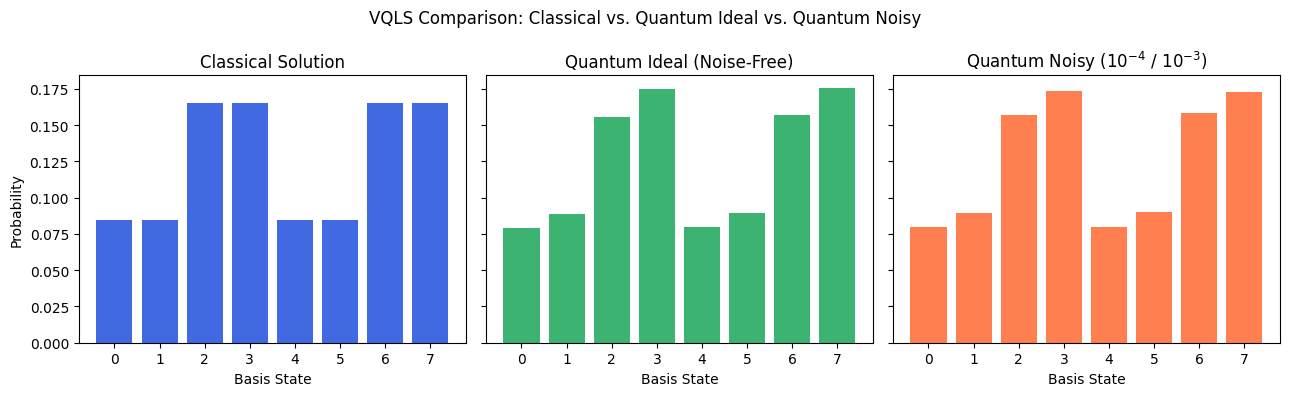

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit_aer.noise as noise

# ==========================================
# 1. Setup & Custom Noise Model Definition
# ==========================================
n_qubits = 3             # System qubits
ancilla_idx = n_qubits   # Ancilla qubit index (qubit 3)
tot_qubits = n_qubits + 1 
shots = 100000
c = np.array([1.0, 0.2, 0.2])  # Linear combination coefficients

# Gates noise error rates
p_1qubit = 1e-5  # 10^-5 for 1-qubit gates
p_2qubit = 1e-4  # 10^-4 for 2-qubit gates

# Construct Qiskit Aer depolarizing noise model
noise_model = noise.NoiseModel()
error_1 = noise.depolarizing_error(p_1qubit, 1)
error_2 = noise.depolarizing_error(p_2qubit, 2)

# Apply 1-qubit gate errors
noise_model.add_all_qubit_quantum_error(error_1, ["h", "ry", "p"])
# Apply 2-qubit gate errors
noise_model.add_all_qubit_quantum_error(error_2, ["cx", "cz"])

# Simulators
ideal_backend = AerSimulator()
noisy_backend = AerSimulator(noise_model=noise_model)

# Classical problem matrices
Id, Z, X = np.identity(2), np.array([[1, 0], [0, -1]]), np.array([[0, 1], [1, 0]])
A_0, A_1, A_2 = np.identity(8), np.kron(np.kron(X, Z), Id), np.kron(np.kron(X, Id), Id)
A_num = c[0] * A_0 + c[1] * A_1 + c[2] * A_2
b_vec = np.ones(8) / np.sqrt(8)


# ==========================================
# 2. Quantum Circuit Subroutines
# ==========================================
def apply_U_b(qc: QuantumCircuit):
    for idx in range(n_qubits):
        qc.h(idx)

def apply_CA(qc: QuantumCircuit, idx: int):
    if idx == 1:
        qc.cx(ancilla_idx, 0)
        qc.cz(ancilla_idx, 1)
    elif idx == 2:
        qc.cx(ancilla_idx, 0)

def apply_variational_block(qc: QuantumCircuit, weights: np.ndarray):
    for idx in range(n_qubits):
        qc.h(idx)
    for idx, w in enumerate(weights):
        qc.ry(w, idx)


# ==========================================
# 3. Hadamard Test & Cost Function Evaluation
# ==========================================
def local_hadamard_test_circuit(weights: np.ndarray, l: int, lp: int, j: int, part: str) -> QuantumCircuit:
    qc = QuantumCircuit(tot_qubits, 1)

    qc.h(ancilla_idx)
    if part.lower() in ["im", "imag"]:
        qc.p(-np.pi / 2, ancilla_idx)

    apply_variational_block(qc, weights)
    apply_CA(qc, l)
    apply_U_b(qc)

    if j != -1:
        qc.cz(ancilla_idx, j)

    apply_U_b(qc)
    apply_CA(qc, lp)
    qc.h(ancilla_idx)

    qc.measure(ancilla_idx, 0)
    return qc

def get_hadamard_test_expval(weights: np.ndarray, l: int, lp: int, j: int, part: str, backend) -> float:
    qc = local_hadamard_test_circuit(weights, l, lp, j, part)
    result = backend.run(qc, shots=shots).result()
    counts = result.get_counts()
    
    p0 = counts.get('0', 0) / shots
    p1 = counts.get('1', 0) / shots
    return p0 - p1

def mu(weights: np.ndarray, l: int, lp: int, j: int, backend) -> complex:
    re = get_hadamard_test_expval(weights, l, lp, j, "Re", backend)
    im = get_hadamard_test_expval(weights, l, lp, j, "Im", backend)
    return re + 1.0j * im

def psi_norm(weights: np.ndarray, backend) -> float:
    norm = 0.0
    for l in range(len(c)):
        for lp in range(len(c)):
            norm += c[l] * np.conj(c[lp]) * mu(weights, l, lp, -1, backend)
    return float(np.abs(norm))

def cost_loc(weights: np.ndarray, backend) -> float:
    mu_sum = 0.0
    for l in range(len(c)):
        for lp in range(len(c)):
            for j in range(n_qubits):
                mu_sum += c[l] * np.conj(c[lp]) * mu(weights, l, lp, j, backend)
    
    mu_sum = np.abs(mu_sum)
    return 0.5 - 0.5 * mu_sum / (n_qubits * psi_norm(weights, backend))


# ==========================================
# 4. Optimization (25 Max Iterations / Steps)
# ==========================================
np.random.seed(0)
initial_weights = 0.001 * np.random.randn(n_qubits)

cost_history = []
def callback(weights):
    c_val = cost_loc(weights, ideal_backend)
    cost_history.append(c_val)
    print(f"Step {len(cost_history):2d} | Cost_L = {c_val:.7f}")

print("--- Starting VQLS Optimization (25 steps) ---")
res = minimize(
    lambda w: cost_loc(w, ideal_backend), 
    initial_weights, 
    method="COBYLA", 
    callback=callback, 
    options={"maxiter": 25}
)
opt_weights = res.x


# ==========================================
# 5. Compute Probabilities for Comparison
# ==========================================
# A. Classical Matrix Inversion Solution
A_inv = np.linalg.inv(A_num)
x_class = np.dot(A_inv, b_vec)
c_probs = (x_class / np.linalg.norm(x_class)) ** 2

# Helper function to sample quantum ansatz circuit
def get_quantum_probabilities(weights: np.ndarray, backend) -> np.ndarray:
    ansatz_qc = QuantumCircuit(n_qubits, n_qubits)
    apply_variational_block(ansatz_qc, weights)
    ansatz_qc.measure(range(n_qubits), range(n_qubits))

    counts = backend.run(ansatz_qc, shots=shots).result().get_counts()
    
    probs = np.zeros(2**n_qubits)
    for bitstr, count in counts.items():
        idx = int(bitstr, 2)
        probs[idx] = count / shots
    return probs

# B. Quantum Ideal (No noise)
q_probs_ideal = get_quantum_probabilities(opt_weights, ideal_backend)

# C. Quantum Noisy (With custom gate noise)
q_probs_noisy = get_quantum_probabilities(opt_weights, noisy_backend)


# ==========================================
# 6. Results & Plot Comparison
# ==========================================
print("\n--- Results Comparison ---")
print("Classical Probabilities :", np.round(c_probs, 4))
print("Quantum Ideal (No Noise):", np.round(q_probs_ideal, 4))
print("Quantum Noisy (With Gate Noise):", np.round(q_probs_noisy, 4))

# Side-by-side plot comparison
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

basis_states = np.arange(2**n_qubits)

axes[0].bar(basis_states, c_probs, color="royalblue")
axes[0].set_title("Classical Solution")
axes[0].set_xlabel("Basis State")
axes[0].set_ylabel("Probability")

axes[1].bar(basis_states, q_probs_ideal, color="mediumseagreen")
axes[1].set_title("Quantum Ideal (Noise-Free)")
axes[1].set_xlabel("Basis State")

axes[2].bar(basis_states, q_probs_noisy, color="coral")
axes[2].set_title("Quantum Noisy ($10^{-4}$ / $10^{-3}$)")
axes[2].set_xlabel("Basis State")

plt.suptitle("VQLS Comparison: Classical vs. Quantum Ideal vs. Quantum Noisy", fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit_aer.noise as noise

# ==========================================
# 1. Setup & Custom Noise Model Definition
# ==========================================
n_qubits = 5             # System qubits updated to 5
ancilla_idx = n_qubits   # Ancilla qubit index (qubit 5)
tot_qubits = n_qubits + 1 
shots = 5000             # Shots updated to 1000
c = np.array([1.0, 0.2, 0.2])  # Linear combination coefficients

# Gates noise error rates
p_1qubit = 1e-5  # 10^-5 for 1-qubit gates
p_2qubit = 1e-4  # 10^-4 for 2-qubit gates

# Construct Qiskit Aer depolarizing noise model
noise_model = noise.NoiseModel()
error_1 = noise.depolarizing_error(p_1qubit, 1)
error_2 = noise.depolarizing_error(p_2qubit, 2)

# Apply 1-qubit gate errors
noise_model.add_all_qubit_quantum_error(error_1, ["h", "ry", "p"])
# Apply 2-qubit gate errors
noise_model.add_all_qubit_quantum_error(error_2, ["cx", "cz"])

# Simulators
ideal_backend = AerSimulator()
noisy_backend = AerSimulator(noise_model=noise_model)

# Classical problem matrices scaled to 5 qubits (2^5 = 32 dimensions)
Id = np.identity(2)
Id3 = np.identity(8)  # 3-qubit Identity (8x8) to make 5 qubits total (2 * 2 * 8 = 32)
Z = np.array([[1, 0], [0, -1]])
X = np.array([[0, 1], [1, 0]])

A_0 = np.identity(32)
A_1 = np.kron(np.kron(X, Z), Id3)   # X_0 Z_1 I_2 I_3 I_4 (32x32)
A_2 = np.kron(np.kron(X, Id), Id3)  # X_0 I_1 I_2 I_3 I_4 (32x32)
A_num = c[0] * A_0 + c[1] * A_1 + c[2] * A_2
b_vec = np.ones(32) / np.sqrt(32)


# ==========================================
# 2. Quantum Circuit Subroutines
# ==========================================
def apply_U_b(qc: QuantumCircuit):
    for idx in range(n_qubits):
        qc.h(idx)

def apply_CA(qc: QuantumCircuit, idx: int):
    if idx == 1:
        qc.cx(ancilla_idx, 0)
        qc.cz(ancilla_idx, 1)
    elif idx == 2:
        qc.cx(ancilla_idx, 0)

def apply_variational_block(qc: QuantumCircuit, weights: np.ndarray):
    for idx in range(n_qubits):
        qc.h(idx)
    for idx, w in enumerate(weights):
        qc.ry(w, idx)


# ==========================================
# 3. Hadamard Test & Cost Function Evaluation
# ==========================================
def local_hadamard_test_circuit(weights: np.ndarray, l: int, lp: int, j: int, part: str) -> QuantumCircuit:
    qc = QuantumCircuit(tot_qubits, 1)

    qc.h(ancilla_idx)
    if part.lower() in ["im", "imag"]:
        qc.p(-np.pi / 2, ancilla_idx)

    apply_variational_block(qc, weights)
    apply_CA(qc, l)
    apply_U_b(qc)

    if j != -1:
        qc.cz(ancilla_idx, j)

    apply_U_b(qc)
    apply_CA(qc, lp)
    qc.h(ancilla_idx)

    qc.measure(ancilla_idx, 0)
    return qc

--- Circuit 1: Subroutines Demonstration ---


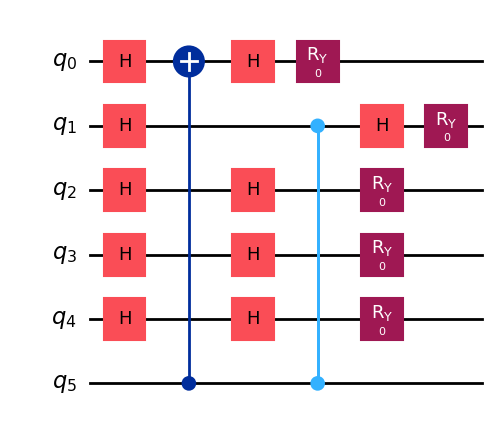

In [10]:
# ==========================================
# Circuit Visualizations
# ==========================================
dummy_weights = np.zeros(n_qubits)

# Circuit 1: Combined Subroutines (apply_U_b, apply_CA, apply_variational_block)
demo_qc = QuantumCircuit(tot_qubits)
apply_U_b(demo_qc)
apply_CA(demo_qc, idx=1)
apply_variational_block(demo_qc, dummy_weights)

print("--- Circuit 1: Subroutines Demonstration ---")
demo_qc.draw(output="mpl", style="iqp", fold=False)


--- Circuit 2: Full Hadamard Test Circuit ---


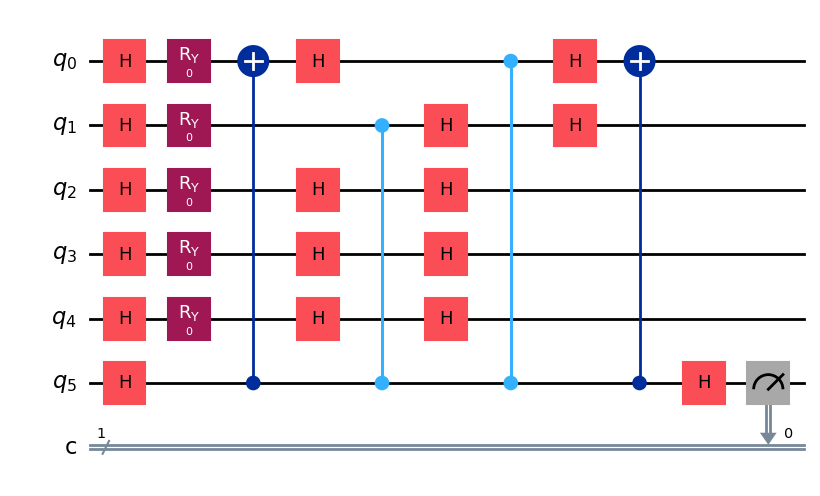

In [11]:
# Circuit 2: Full Hadamard Test Circuit
hadamard_demo_qc = local_hadamard_test_circuit(dummy_weights, l=1, lp=2, j=0, part="Re")

print("\n--- Circuit 2: Full Hadamard Test Circuit ---")
hadamard_demo_qc.draw(output="mpl", style="iqp", fold=False)

--- Starting VQLS Optimization (50 steps) ---
Step  1 | Cost_L = 0.0059500
Step  2 | Cost_L = 0.0065176
Step  3 | Cost_L = 0.0038293
Step  4 | Cost_L = 0.0068701
Step  5 | Cost_L = 0.0042397
Step  6 | Cost_L = 0.0043080
Step  7 | Cost_L = 0.0029779
Step  8 | Cost_L = 0.0054798
Step  9 | Cost_L = 0.0052943
Step 10 | Cost_L = 0.0033811
Step 11 | Cost_L = 0.0055782
Step 12 | Cost_L = 0.0050228
Step 13 | Cost_L = 0.0018794
Step 14 | Cost_L = 0.0051653
Step 15 | Cost_L = 0.0018048
Step 16 | Cost_L = 0.0057057
Step 17 | Cost_L = 0.0036148
Step 18 | Cost_L = 0.0046162
Step 19 | Cost_L = 0.0047097
Step 20 | Cost_L = 0.0017174
Step 21 | Cost_L = 0.0040572

--- Results Comparison ---
Classical Probabilities : [0.0211 0.0211 0.0211 0.0211 0.0211 0.0211 0.0211 0.0211 0.0414 0.0414
 0.0414 0.0414 0.0414 0.0414 0.0414 0.0414 0.0211 0.0211 0.0211 0.0211
 0.0211 0.0211 0.0211 0.0211 0.0414 0.0414 0.0414 0.0414 0.0414 0.0414
 0.0414 0.0414]
Quantum Ideal (No Noise): [0.0326 0.032  0.0342 0.039  0.0316 

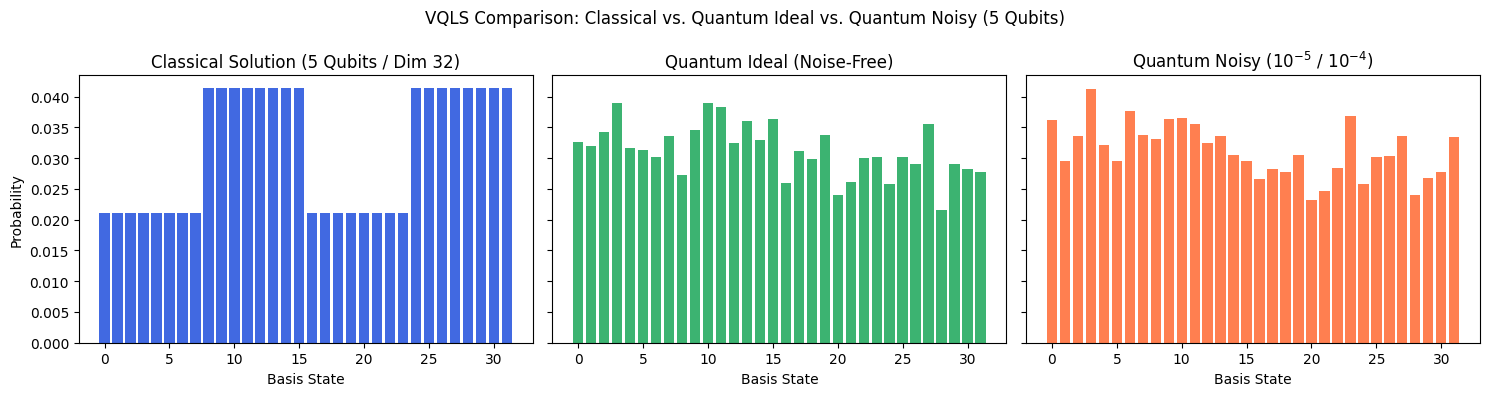

In [12]:
def get_hadamard_test_expval(weights: np.ndarray, l: int, lp: int, j: int, part: str, backend) -> float:
    qc = local_hadamard_test_circuit(weights, l, lp, j, part)
    result = backend.run(qc, shots=shots).result()
    counts = result.get_counts()
    
    p0 = counts.get('0', 0) / shots
    p1 = counts.get('1', 0) / shots
    return p0 - p1

def mu(weights: np.ndarray, l: int, lp: int, j: int, backend) -> complex:
    re = get_hadamard_test_expval(weights, l, lp, j, "Re", backend)
    im = get_hadamard_test_expval(weights, l, lp, j, "Im", backend)
    return re + 1.0j * im

def psi_norm(weights: np.ndarray, backend) -> float:
    norm = 0.0
    for l in range(len(c)):
        for lp in range(len(c)):
            norm += c[l] * np.conj(c[lp]) * mu(weights, l, lp, -1, backend)
    return float(np.abs(norm))

def cost_loc(weights: np.ndarray, backend) -> float:
    mu_sum = 0.0
    for l in range(len(c)):
        for lp in range(len(c)):
            for j in range(n_qubits):
                mu_sum += c[l] * np.conj(c[lp]) * mu(weights, l, lp, j, backend)
    
    mu_sum = np.abs(mu_sum)
    return 0.5 - 0.5 * mu_sum / (n_qubits * psi_norm(weights, backend))


# ==========================================
# 4. Optimization (50 Max Iterations / Steps)
# ==========================================
np.random.seed(0)
initial_weights = 0.001 * np.random.randn(n_qubits)

cost_history = []
def callback(weights):
    c_val = cost_loc(weights, ideal_backend)
    cost_history.append(c_val)
    print(f"Step {len(cost_history):2d} | Cost_L = {c_val:.7f}")

print("--- Starting VQLS Optimization (50 steps) ---")
res = minimize(
    lambda w: cost_loc(w, ideal_backend), 
    initial_weights, 
    method="COBYLA", 
    callback=callback, 
    options={"maxiter": 50}
)
opt_weights = res.x


# ==========================================
# 5. Compute Probabilities for Comparison
# ==========================================
# A. Classical Matrix Inversion Solution
A_inv = np.linalg.inv(A_num)
x_class = np.dot(A_inv, b_vec)
c_probs = (x_class / np.linalg.norm(x_class)) ** 2

# Helper function to sample quantum ansatz circuit
def get_quantum_probabilities(weights: np.ndarray, backend) -> np.ndarray:
    ansatz_qc = QuantumCircuit(n_qubits, n_qubits)
    apply_variational_block(ansatz_qc, weights)
    ansatz_qc.measure(range(n_qubits), range(n_qubits))

    counts = backend.run(ansatz_qc, shots=shots).result().get_counts()
    
    probs = np.zeros(2**n_qubits)
    for bitstr, count in counts.items():
        idx = int(bitstr, 2)
        probs[idx] = count / shots
    return probs

# B. Quantum Ideal (No noise)
q_probs_ideal = get_quantum_probabilities(opt_weights, ideal_backend)

# C. Quantum Noisy (With custom gate noise)
q_probs_noisy = get_quantum_probabilities(opt_weights, noisy_backend)


# ==========================================
# 6. Results & Plot Comparison
# ==========================================
print("\n--- Results Comparison ---")
print("Classical Probabilities :", np.round(c_probs, 4))
print("Quantum Ideal (No Noise):", np.round(q_probs_ideal, 4))
print("Quantum Noisy (With Gate Noise):", np.round(q_probs_noisy, 4))

# Side-by-side plot comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

basis_states = np.arange(2**n_qubits)

axes[0].bar(basis_states, c_probs, color="royalblue")
axes[0].set_title("Classical Solution (5 Qubits / Dim 32)")
axes[0].set_xlabel("Basis State")
axes[0].set_ylabel("Probability")

axes[1].bar(basis_states, q_probs_ideal, color="mediumseagreen")
axes[1].set_title("Quantum Ideal (Noise-Free)")
axes[1].set_xlabel("Basis State")

axes[2].bar(basis_states, q_probs_noisy, color="coral")
axes[2].set_title("Quantum Noisy ($10^{-5}$ / $10^{-4}$)")
axes[2].set_xlabel("Basis State")

plt.suptitle("VQLS Comparison: Classical vs. Quantum Ideal vs. Quantum Noisy (5 Qubits)", fontsize=12)
plt.tight_layout()
plt.show()